## 1. Import Libraries and Load the Image

We begin by importing the libraries required for image processing and visualization.

- **OpenCV (`cv2`)** is used to load and process images.
- **Matplotlib (`matplotlib.pyplot`)** is used to display images and compare preprocessing results.
- **Path (`pathlib`)** helps construct file paths in a platform-independent way.

We load the nutrition-label image from the project's `data/sample_images` directory.

The `cv2.imread()` function reads the image from disk. If the image cannot be loaded, it returns `None`, so we check for this condition before proceeding.

OpenCV loads color images in **BGR format**, while Matplotlib expects **RGB format**. We convert BGR to RGB before displaying the original image.

In [5]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

project_root = Path.cwd().parent

image_path = (
    project_root
    / "data"
    / "sample_images"
    / "nutrition_label.png"
)

print("Image exists:", image_path.exists())

Image exists: True


## 2. Understanding Image Properties

Before preprocessing an image, we inspect its dimensions and channel structure.

The `shape` attribute returns the dimensions of a NumPy image array.

For a color image, the shape is generally `(height, width, channels)`. Our nutrition-label image has dimensions `(675, 346, 3)`.

This means:
- Height: 675 pixels
- Width: 346 pixels
- Color channels: 3 (Blue, Green, Red)

The image contains 233,550 pixels, with three color-channel values per pixel.

Understanding image dimensions helps us select suitable preprocessing techniques and verify that images have loaded correctly.

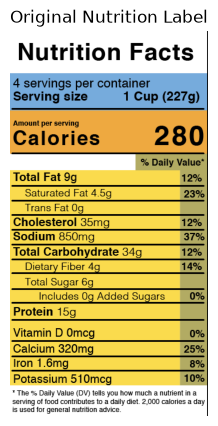

In [4]:
image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 5))
plt.imshow(image_rgb)
plt.title("Original Nutrition Label")
plt.axis("off");

## 3. Grayscale Conversion

Grayscale conversion transforms a color image into an image with a single intensity value per pixel.

Instead of representing each pixel using three color channels, a grayscale image represents it using one intensity channel, typically ranging from 0 (black) to 255 (white).

We use OpenCV's `cv2.cvtColor()` function with `cv2.COLOR_BGR2GRAY` to perform this conversion.

Grayscale images can simplify certain OCR preprocessing steps because color information is often unnecessary for reading printed text.

**Observation:** The grayscale image retains the important visual information in our nutrition label. However, whether grayscale improves recognition must be evaluated using the OCR output rather than visual appearance alone.

Original: (675, 346, 3)
Grayscale: (675, 346)


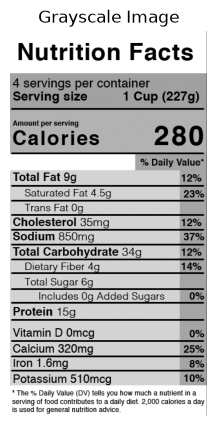

In [5]:
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Original:", image.shape)
print("Grayscale:", gray_image.shape)

plt.figure(figsize=(8, 5))
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off");

## 4. Global Thresholding

Thresholding converts a grayscale image into a binary image containing black and white pixels.

In global thresholding, a single threshold value is applied to the entire image.

We use `cv2.threshold()` with `cv2.THRESH_BINARY`. Pixels above the threshold become white (255), while pixels at or below the threshold become black (0).

We experiment with threshold values of 100, 150, and 200 to observe how the appearance of text changes.

A low threshold may preserve some darker details but can make the background less clean. A high threshold can remove faint text or thin character strokes.

**Observation:** A threshold value of 150 appeared visually suitable for our sample, but some text became less visible. The best threshold depends on the image and should ultimately be evaluated by OCR accuracy.

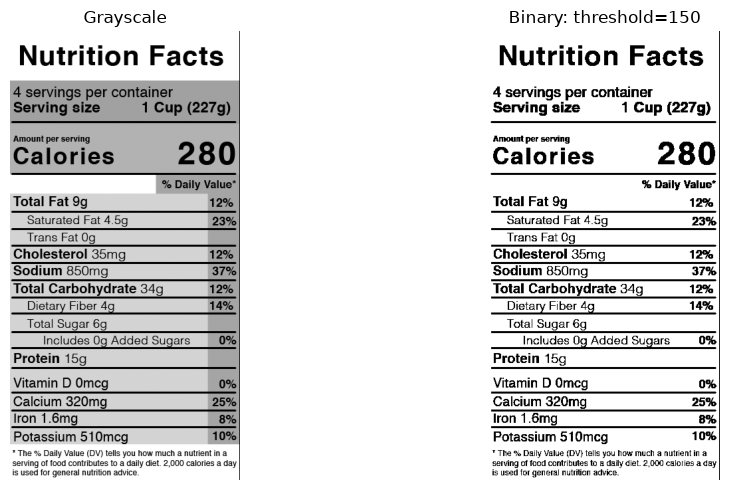

In [6]:
threshold_value = 150

_, binary_image = cv2.threshold(
    gray_image,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(gray_image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Grayscale")
axes[0].axis("off")

axes[1].imshow(binary_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Binary: threshold={threshold_value}")
axes[1].axis("off")

plt.tight_layout()

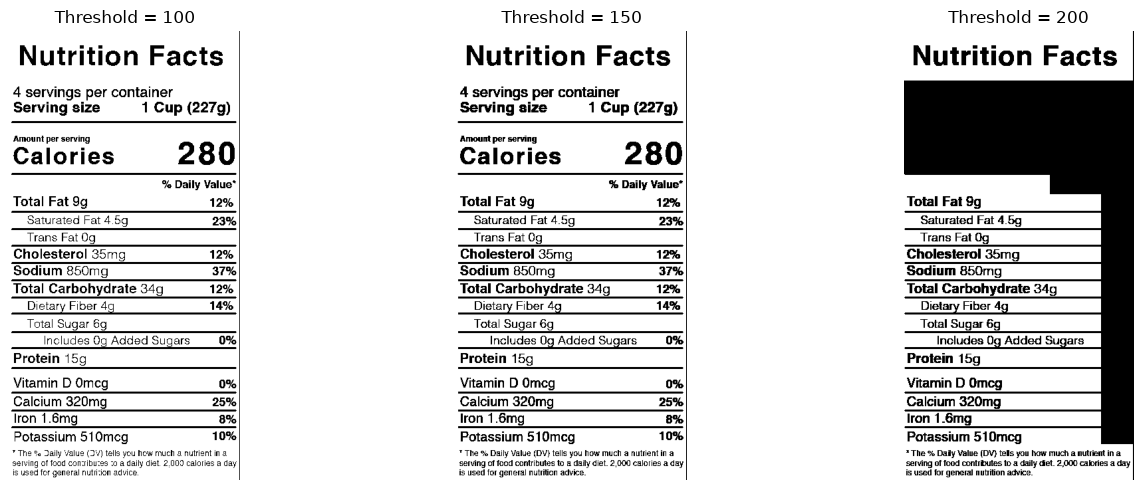

In [8]:
thresholds = [100,150,200]

fig, axes = plt.subplots(1, 3, figsize=(15,5))

for ax, value in zip(axes, thresholds):
    _, result = cv2.threshold(
        gray_image,
        value,
        255,
        cv2.THRESH_BINARY
    )

    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Threshold = {value}")
    ax.axis("off")

plt.tight_layout()

## 5. Adaptive Thresholding

Global thresholding applies the same threshold to the entire image. This can be less effective when lighting or background brightness varies across an image.

Adaptive thresholding calculates local thresholds using neighborhoods of pixels.

We use `cv2.adaptiveThreshold()` with the Gaussian adaptive method and binary output.

The parameters include:
- `gray_image`: the grayscale input image.
- `255`: the maximum output intensity.
- `cv2.ADAPTIVE_THRESH_GAUSSIAN_C`: calculates a locally weighted threshold.
- `cv2.THRESH_BINARY`: produces a black-and-white image.
- `31`: the neighborhood block size, which must be odd and greater than 1.
- `10`: the constant subtracted from the calculated local threshold.

Adaptive thresholding can help with uneven lighting, but it does not always improve OCR.

**Observation:** For our sample image, adaptive thresholding did not provide a clear visual improvement. We will compare recognition results before deciding whether to use it.

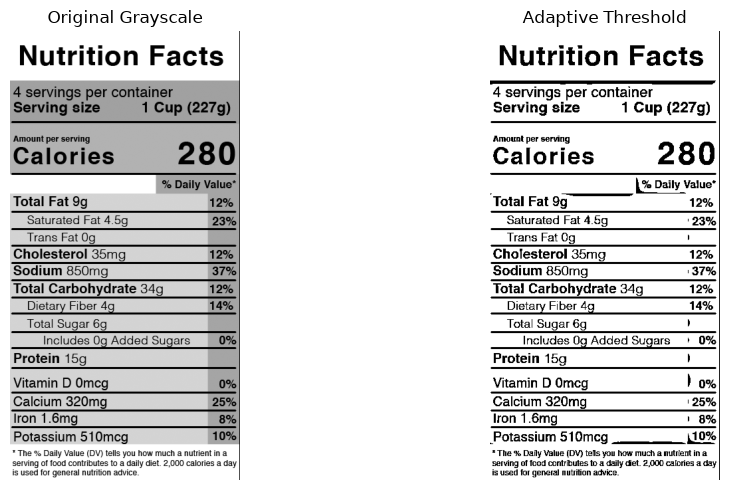

In [9]:
adaptive_image = cv2.adaptiveThreshold(
    gray_image,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    10
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(gray_image, cmap="gray")
axes[0].set_title("Original Grayscale")
axes[0].axis("off")

axes[1].imshow(adaptive_image, cmap="gray")
axes[1].set_title("Adaptive Threshold")
axes[1].axis("off")

plt.tight_layout()

## 6. Image Resizing

Image resizing changes an image's width and height.

We use `cv2.resize()` with scaling factors `fx=2` and `fy=2`, which doubles the image dimensions in both directions.

The `cv2.INTER_CUBIC` interpolation method estimates new pixel values using neighboring pixels. It is commonly used when enlarging images.

Our grayscale image changes from `(675, 346)` to `(1350, 692)`.

Resizing can help OCR when the original text is too small to recognize. However, enlarging an already readable image does not necessarily add useful information.

**Observation:** Our original image already contains reasonably clear text, and resizing did not noticeably improve its appearance. We will retain resizing as an optional preprocessing technique rather than applying it automatically.

Original grayscale: (675, 346)
Resized image: (1350, 692)


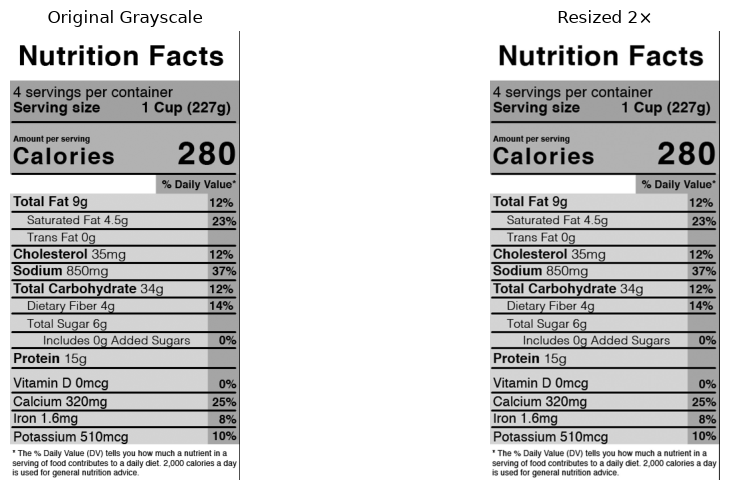

In [11]:
# Enlarge the grayscale image by 2 times
scale_factor = 2

resized_image = cv2.resize(
    gray_image,
    None,
    fx=scale_factor,
    fy=scale_factor,
    interpolation=cv2.INTER_CUBIC
)

print("Original grayscale:", gray_image.shape)
print("Resized image:", resized_image.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(gray_image, cmap="gray")
axes[0].set_title("Original Grayscale")
axes[0].axis("off")

axes[1].imshow(resized_image, cmap="gray")
axes[1].set_title("Resized 2×")
axes[1].axis("off")

plt.tight_layout()

## 7. Setting Up Tesseract OCR

Tesseract is an OCR (Optical Character Recognition) engine that recognizes text in images.

We use the Python package `pytesseract` to communicate with the Tesseract executable.

Installing `pytesseract` alone does not install the OCR engine. Both the Python wrapper and the Tesseract executable must be available.

Because the executable is installed in a user-specific Windows directory, we explicitly configure its path through `pytesseract.pytesseract.tesseract_cmd`.

This configuration allows Python to locate and run the OCR engine even if its installation directory has not been added to the Windows PATH environment variable.

In [16]:
import os 
import pytesseract

tesseract_path = os.getenv("TESSERACT_CMD")

if tesseract_path:
    pytesseract.pytesseract.tesseract_cmd = tesseract_path

print(pytesseract.get_tesseract_version())

5.4.0.20240606


## 8. Extracting Text from the Original Image

We perform our first OCR experiment using `pytesseract.image_to_string()`.

This function accepts an image and returns the recognized text as a Python string.

The extracted text may contain nutrition values, units, serving information, and explanatory statements.

OCR output can include spelling errors, missing characters, incorrect units, or confusion between similar-looking characters such as `0` and `O`.

We preserve the raw output before making any corrections so that later processing can be compared against the original recognition result.

In [13]:
import pytesseract

extracted_text = pytesseract.image_to_string(image)

print(extracted_text)

Nutrition Facts

4 servings per container
Serving size 1 Cup (227g)

‘Amount per serving

Calories 280

% Daily Value*
Total Fat 9g 12%
Saturated Fat 4.59 23%
Trans Fat 0g
Cholesterol 35mg 12%
Sodium 850mg 37%
Total Carbohydrate 34g 12%
Dietary Fiber 4g 14%

Total Sugar 6g

Includes Og Added Sugars 0%
Protein 15g

Vitamin D Omeg 0%
Calcium 320mg 25%
Iron 1.6mg 8%
Potassium 510mcg 10%

* The % Daily Value (DV) tells you how much a nutrient in a
serving of food conttibutes to a daily diet. 2,000 calories a day
is used for general nutrition advice.




## 9. Comparing Original and Grayscale OCR

We compare OCR results obtained from the original color image and the grayscale image.

The purpose is to determine whether grayscale conversion improves the recognition of words, numbers, and units.

**Observation:** Both images produced identical OCR output for our sample. Therefore, grayscale conversion did not measurably improve the recognized text in this experiment.

This does not mean grayscale is ineffective for all images. Its usefulness depends on image quality, contrast, lighting, and text characteristics.

For this sample, the original image serves as our baseline. We avoid adding preprocessing steps unless they provide a measurable benefit.

In [14]:
original_text = pytesseract.image_to_string(image)
grayscale_text = pytesseract.image_to_string(gray_image)

print("===== ORIGINAL IMAGE =====")
print(original_text)

print("\n===== GRAYSCALE IMAGE =====")
print(grayscale_text)

===== ORIGINAL IMAGE =====
Nutrition Facts

4 servings per container
Serving size 1 Cup (227g)

‘Amount per serving

Calories 280

% Daily Value*
Total Fat 9g 12%
Saturated Fat 4.59 23%
Trans Fat 0g
Cholesterol 35mg 12%
Sodium 850mg 37%
Total Carbohydrate 34g 12%
Dietary Fiber 4g 14%

Total Sugar 6g

Includes Og Added Sugars 0%
Protein 15g

Vitamin D Omeg 0%
Calcium 320mg 25%
Iron 1.6mg 8%
Potassium 510mcg 10%

* The % Daily Value (DV) tells you how much a nutrient in a
serving of food conttibutes to a daily diet. 2,000 calories a day
is used for general nutrition advice.



===== GRAYSCALE IMAGE =====
Nutrition Facts

4 servings per container
Serving size 1 Cup (227g)

‘Amount per serving

Calories 280

% Daily Value*
Total Fat 9g 12%
Saturated Fat 4.59 23%
Trans Fat 0g
Cholesterol 35mg 12%
Sodium 850mg 37%
Total Carbohydrate 34g 12%
Dietary Fiber 4g 14%

Total Sugar 6g

Includes Og Added Sugars 0%
Protein 15g

Vitamin D Omeg 0%
Calcium 320mg 25%
Iron 1.6mg 8%
Potassium 510mcg 10%

* 

## 10. OCR on the Threshold Image

We apply Tesseract to the binary image generated using global thresholding.

Comparing this output with the original and grayscale results helps us determine whether converting the image to black and white improves recognition.

**Observation:** Thresholding correctly recognized `0g` in the added-sugars line and `contributes` in the explanatory paragraph. However, the potassium unit was recognized as `510meg` rather than `510mcg`.

This demonstrates that preprocessing can correct some recognition errors while introducing or retaining others.

We should not select a preprocessing method based on a few words alone. A larger set of labels and a systematic comparison would provide a more reliable evaluation.

In [16]:
threshold_text = pytesseract.image_to_string(binary_image)

print("===== THRESHOLD IMAGE =====")
print(threshold_text)

===== THRESHOLD IMAGE =====
Nutrition Facts

4 servings per container
Serving size 1 Cup (227g)

‘Amount per serving

Calories 280

% Daily Value”
Total Fat 9g 12%
Saturated Fat 4.59 23%
Trans Fat 0g
Cholesterol 35mg 12%
Sodium 850mg 37%
Total Carbohydrate 34g 12%
Dietary Fiber 4g 14%

Total Sugar 6g

Includes 0g Added Sugars 0%
Protein 15g

Vitamin D Omeg 0%

Calcium 320mg 25%
Iron 1.6mg 8%
Potassium 510meg 10%

* The % Daily Value (DV) tells you how much a nutrient in a
serving of food contributes to a daily diet. 2,000 calories a day
is used for general nutrition advice.




## 11. Understanding OCR Confidence Scores

Tesseract can return detailed recognition information using `pytesseract.image_to_data()`.

By specifying `output_type=pytesseract.Output.DICT`, we receive a dictionary containing recognized text, confidence scores, word positions, and other layout information.

The `text` and `conf` entries contain corresponding text and confidence values. We use `zip()` to pair each recognized text entry with its confidence score.

An OCR confidence score indicates how confident Tesseract is about a recognition result. It is not a calibrated probability that the result is correct.

For example, `4.59` received a confidence score of 59, while `Og` received 88 despite potentially being a misrecognition of `0g`.

We use confidence scores to help identify text that may need review, but we do not treat them as proof of correctness.

In [20]:
ocr_data = pytesseract.image_to_data(
    image,
    output_type=pytesseract.Output.DICT
)

for word, confidence in zip(
    ocr_data["text"],
    ocr_data["conf"]
):
    if word.strip():
        print(f"{word:20} Confidence: {confidence}")

Nutrition            Confidence: 95
Facts                Confidence: 96
4                    Confidence: 96
servings             Confidence: 96
per                  Confidence: 96
container            Confidence: 96
Serving              Confidence: 96
size                 Confidence: 96
1                    Confidence: 94
Cup                  Confidence: 94
(227g)               Confidence: 87
‘Amount              Confidence: 80
per                  Confidence: 96
serving              Confidence: 96
Calories             Confidence: 95
280                  Confidence: 96
%                    Confidence: 89
Daily                Confidence: 93
Value*               Confidence: 91
Total                Confidence: 96
Fat                  Confidence: 96
9g                   Confidence: 66
12%                  Confidence: 96
Saturated            Confidence: 96
Fat                  Confidence: 96
4.59                 Confidence: 59
23%                  Confidence: 94
Trans                Confide

## 12. Filtering Low-Confidence OCR Results

Tesseract provides a confidence score for each recognized word. These scores help us identify words that may need manual review.

In this section, we filter words with confidence scores below 80 to flag potentially unreliable OCR results.

**Important:** A low confidence score does not always mean the word is incorrect, and a high score does not guarantee correctness. We should verify suspicious nutrition values against the original image.

In [25]:
for word, confidence in zip(
    ocr_data["text"],
    ocr_data["conf"]
):
    if (
        word.strip()
        and confidence != "-1"
        and float(confidence) < 80
    ):
        print(f"{word:20} Confidence: {confidence}")

9g                   Confidence: 66
4.59                 Confidence: 59
serving              Confidence: 26
conttibutes          Confidence: 79


## 13. Extracting Structured Nutrition Data

Raw OCR text is not yet in a convenient format for an application. We need to identify individual nutrient labels and associate them with their recognized values.

We use Python's `re` module, which supports regular expressions, to search for specific nutrient names at the beginning of each line.

The pattern captures the text following a nutrient label. We store the results in a Python dictionary, using nutrient names as keys and recognized values as values.

For example, `Sodium 850mg 37%` is initially stored as `850mg 37%`.

This approach is suitable for our initial experiment but depends on labels appearing in recognizable line formats. Other label layouts and OCR errors may require more flexible extraction rules.

At this stage, we preserve recognized values rather than silently correcting them.

In [22]:
import re

# Use the OCR output from the original image
text_to_parse = original_text

nutrients = [
    "Calories",
    "Total Fat",
    "Saturated Fat",
    "Cholesterol",
    "Sodium",
    "Total Carbohydrate",
    "Dietary Fiber",
    "Total Sugar",
    "Protein",
    "Calcium",
    "Iron",
    "Potassium"
]

nutrition_data = {}

for nutrient in nutrients:
    pattern = rf"^\s*{re.escape(nutrient)}\s+(.+?)\s*$"

    match = re.search(
        pattern,
        text_to_parse,
        flags=re.IGNORECASE | re.MULTILINE
    )

    if match:
        nutrition_data[nutrient] = match.group(1).strip()
    else:
        nutrition_data[nutrient] = None

for nutrient, value in nutrition_data.items():
    print(f"{nutrient}: {value}")

Calories: 280
Total Fat: 9g 12%
Saturated Fat: 4.59 23%
Cholesterol: 35mg 12%
Sodium: 850mg 37%
Total Carbohydrate: 34g 12%
Dietary Fiber: 4g 14%
Total Sugar: 6g
Protein: 15g
Calcium: 320mg 25%
Iron: 1.6mg 8%
Potassium: 510mcg 10%


## 14. Separating Amounts and Daily Value Percentages

Many nutrition labels display both a nutrient amount and a Daily Value percentage.

For example, `Sodium 850mg 37%` contains an amount of `850mg` and a Daily Value of `37%`.

We use a regular expression to identify a percentage at the end of the extracted line and separate it from the preceding amount.

The resulting dictionary stores two fields for each nutrient:
- `amount`: the recognized nutrient amount and unit.
- `daily_value`: the recognized percentage, or `None` when no percentage is present.

Calories, protein, and total sugar may not have a Daily Value percentage in the current extraction output.

We retain the recognized text as strings for now. Numeric conversion and more comprehensive unit validation will be handled separately.

In [23]:
parsed_nutrition = {}

for nutrient, value in nutrition_data.items():
    if value is None:
        parsed_nutrition[nutrient] = {
            "amount": None,
            "daily_value": None
        }
        continue

    match = re.match(
        r"^\s*(.*?)\s+(\d+(?:\.\d+)?)%\s*$",
        value
    )

    if match:
        amount = match.group(1).strip()
        daily_value = match.group(2) + "%"
    else:
        amount = value.strip()
        daily_value = None

    parsed_nutrition[nutrient] = {
        "amount": amount,
        "daily_value": daily_value
    }

for nutrient, details in parsed_nutrition.items():
    print(
        f"{nutrient}: Amount={details['amount']}, "
        f"Daily Value={details['daily_value']}"
    )

Calories: Amount=280, Daily Value=None
Total Fat: Amount=9g, Daily Value=12%
Saturated Fat: Amount=4.59, Daily Value=23%
Cholesterol: Amount=35mg, Daily Value=12%
Sodium: Amount=850mg, Daily Value=37%
Total Carbohydrate: Amount=34g, Daily Value=12%
Dietary Fiber: Amount=4g, Daily Value=14%
Total Sugar: Amount=6g, Daily Value=None
Protein: Amount=15g, Daily Value=None
Calcium: Amount=320mg, Daily Value=25%
Iron: Amount=1.6mg, Daily Value=8%
Potassium: Amount=510mcg, Daily Value=10%


## 15. Validating Extracted Values

OCR can produce values that look plausible but are incorrect. Before using extracted nutrition information, we apply basic validation checks.

Our initial checks look for missing values, absent numeric content, and unexpected units or formats for selected nutrients.

Two values from our sample triggered warnings:

- **Saturated Fat:** `4.59` may be a misrecognition of `4.5g`, but the original label must be checked before making any correction.
- **Potassium:** `510mcg` triggered a unit-format warning because the current rule expects `mg` or `g`. The printed unit must be verified rather than automatically replaced.

These warnings demonstrate the difference between extraction and validation. A warning does not prove that a value is incorrect; it indicates that additional review may be necessary.

The current rules are specific to our sample and will need to become more general as we test additional labels.

In [24]:
validation_warnings = []

for nutrient, details in parsed_nutrition.items():
    amount = details["amount"]

    if amount is None:
        validation_warnings.append(
            f"{nutrient}: Value not found."
        )
        continue

    if nutrient != "Calories" and not re.search(
        r"\d", amount
    ):
        validation_warnings.append(
            f"{nutrient}: No numeric value detected."
        )

    if nutrient == "Saturated Fat" and not re.search(
        r"\d+(?:\.\d+)?\s*g\b",
        amount,
        flags=re.IGNORECASE
    ):
        validation_warnings.append(
            f"{nutrient}: Amount or unit looks suspicious: {amount}"
        )

    if nutrient == "Potassium" and not re.search(
        r"\d+(?:\.\d+)?\s*(?:mg|g)\b",
        amount,
        flags=re.IGNORECASE
    ):
        validation_warnings.append(
            f"{nutrient}: Check the recognized amount and unit: {amount}"
        )

if validation_warnings:
    print("Review these extracted values:")
    for warning in validation_warnings:
        print("-", warning)
else:
    print("No validation warnings.")

Review these extracted values:
- Saturated Fat: Amount or unit looks suspicious: 4.59
- Potassium: Check the recognized amount and unit: 510mcg


## 16. Final Observations and Conclusion

In this notebook, we explored the initial OCR workflow for extracting nutrition information from food labels.

### Key observations

- OpenCV successfully loaded and displayed the nutrition-label image.
- Grayscale conversion produced the same OCR output as the original image in our experiment.
- Global thresholding corrected some recognition errors but did not improve every word or unit.
- Adaptive thresholding and resizing did not provide a clear benefit for this particular sample.
- Tesseract extracted several nutrient names, amounts, and Daily Value percentages.
- Confidence scores helped identify potentially difficult recognition results but did not guarantee correctness.
- Regular expressions allowed us to extract nutrient fields and separate amounts from Daily Value percentages.
- Basic validation identified suspicious values that require inspection.

### Limitations

The experiments used a single sample image, so the findings cannot establish which preprocessing method works best in general. The current extraction and validation rules also depend on recognizable label formats.

### Next steps

We will move reusable code into the Python modules under the `ocr/` directory, test the pipeline on multiple nutrition labels, improve extraction and validation, and connect the OCR pipeline to the AANCHAL application.

**Overall workflow:** Image loading → preprocessing → OCR → structured extraction → validation.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ocr.image_loader import load_image
from ocr.image_preprocessing import (
    convert_to_grayscale,
    apply_threshold,
    apply_adaptive_threshold,
    resize_image,
)
from ocr.text_recognizer import extract_text

In [2]:
image_path = project_root / "data" / "sample_images" / "nutrition_label.png"

image = load_image(image_path)

print("Image loaded successfully!")
print("Image shape:", image.shape)
print("Image data type:", image.dtype)

Image loaded successfully!
Image shape: (675, 346, 3)
Image data type: uint8


In [3]:
gray = convert_to_grayscale(image)

binary = apply_threshold(gray)

adaptive = apply_adaptive_threshold(gray)

resized = resize_image(gray)

print("Grayscale shape:", gray.shape)
print("Binary shape:", binary.shape)
print("Adaptive shape:", adaptive.shape)
print("Resized shape:", resized.shape)

Grayscale shape: (675, 346)
Binary shape: (675, 346)
Adaptive shape: (675, 346)
Resized shape: (1350, 692)


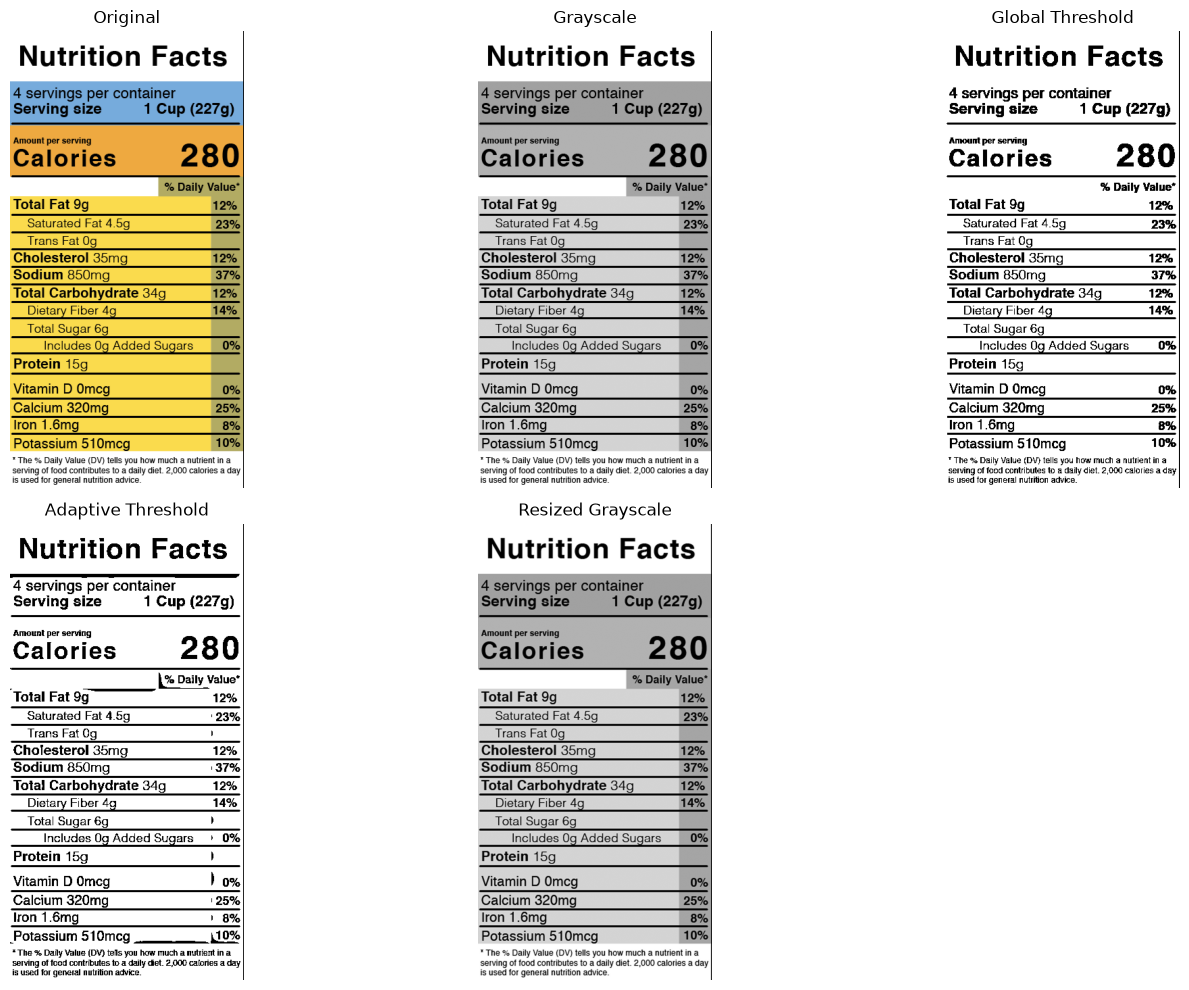

In [6]:
import matplotlib.pyplot as plt

images = [
    ("Original", image),
    ("Grayscale", gray),
    ("Global Threshold", binary),
    ("Adaptive Threshold", adaptive),
    ("Resized Grayscale", resized),
]

plt.figure(figsize=(15, 10))

for index, (title, img) in enumerate(images):
    plt.subplot(2, 3, index + 1)

    if len(img.shape) == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap="gray")

    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
original_text = extract_text(image)

print(original_text)

Nutrition Facts

4 servings per container
Serving size 1 Cup (227g)

‘Amount per serving

Calories 280

% Daily Value*
Total Fat 9g 12%
Saturated Fat 4.59 23%
Trans Fat 0g
Cholesterol 35mg 12%
Sodium 850mg 37%
Total Carbohydrate 34g 12%
Dietary Fiber 4g 14%

Total Sugar 6g

Includes Og Added Sugars 0%
Protein 15g

Vitamin D Omeg 0%
Calcium 320mg 25%
Iron 1.6mg 8%
Potassium 510mcg 10%

* The % Daily Value (DV) tells you how much a nutrient in a
serving of food conttibutes to a daily diet. 2,000 calories a day
is used for general nutrition advice.




In [8]:
gray_text = extract_text(gray)

print(gray_text)

Nutrition Facts

4 servings per container
Serving size 1 Cup (227g)

‘Amount per serving

Calories 280

% Daily Value*
Total Fat 9g 12%
Saturated Fat 4.59 23%
Trans Fat 0g
Cholesterol 35mg 12%
Sodium 850mg 37%
Total Carbohydrate 34g 12%
Dietary Fiber 4g 14%

Total Sugar 6g

Includes Og Added Sugars 0%
Protein 15g

Vitamin D Omeg 0%
Calcium 320mg 25%
Iron 1.6mg 8%
Potassium 510mcg 10%

* The % Daily Value (DV) tells you how much a nutrient in a
serving of food conttibutes to a daily diet. 2,000 calories a day
is used for general nutrition advice.




In [9]:
threshold_text = extract_text(binary)

print(threshold_text)

Nutrition Facts

4 servings per container
Serving size 1 Cup (227g)

‘Amount per serving

Calories 280

% Daily Value”
Total Fat 9g 12%
Saturated Fat 4.59 23%
Trans Fat 0g
Cholesterol 35mg 12%
Sodium 850mg 37%
Total Carbohydrate 34g 12%
Dietary Fiber 4g 14%

Total Sugar 6g

Includes 0g Added Sugars 0%
Protein 15g

Vitamin D Omeg 0%

Calcium 320mg 25%
Iron 1.6mg 8%
Potassium 510meg 10%

* The % Daily Value (DV) tells you how much a nutrient in a
serving of food contributes to a daily diet. 2,000 calories a day
is used for general nutrition advice.




In [10]:
print("ORIGINAL IMAGE OCR")
print("-" * 50)
print(original_text)

print("\nGRAYSCALE IMAGE OCR")
print("-" * 50)
print(gray_text)

print("\nTHRESHOLD IMAGE OCR")
print("-" * 50)
print(threshold_text)

ORIGINAL IMAGE OCR
--------------------------------------------------
Nutrition Facts

4 servings per container
Serving size 1 Cup (227g)

‘Amount per serving

Calories 280

% Daily Value*
Total Fat 9g 12%
Saturated Fat 4.59 23%
Trans Fat 0g
Cholesterol 35mg 12%
Sodium 850mg 37%
Total Carbohydrate 34g 12%
Dietary Fiber 4g 14%

Total Sugar 6g

Includes Og Added Sugars 0%
Protein 15g

Vitamin D Omeg 0%
Calcium 320mg 25%
Iron 1.6mg 8%
Potassium 510mcg 10%

* The % Daily Value (DV) tells you how much a nutrient in a
serving of food conttibutes to a daily diet. 2,000 calories a day
is used for general nutrition advice.



GRAYSCALE IMAGE OCR
--------------------------------------------------
Nutrition Facts

4 servings per container
Serving size 1 Cup (227g)

‘Amount per serving

Calories 280

% Daily Value*
Total Fat 9g 12%
Saturated Fat 4.59 23%
Trans Fat 0g
Cholesterol 35mg 12%
Sodium 850mg 37%
Total Carbohydrate 34g 12%
Dietary Fiber 4g 14%

Total Sugar 6g

Includes Og Added Sugars 0%
P

In [11]:
import importlib
import ocr.text_recognizer as text_recognizer

importlib.reload(text_recognizer)

extract_text = text_recognizer.extract_text
extract_text_with_confidence = text_recognizer.extract_text_with_confidence

In [12]:
ocr_results = extract_text_with_confidence(gray)

for result in ocr_results:
    print(
        f"{result['word']:20}"
        f"Confidence: {result['confidence']}"
    )

Nutrition           Confidence: 95.0
Facts               Confidence: 96.0
4                   Confidence: 96.0
servings            Confidence: 96.0
per                 Confidence: 96.0
container           Confidence: 96.0
Serving             Confidence: 96.0
size                Confidence: 96.0
1                   Confidence: 94.0
Cup                 Confidence: 94.0
(227g)              Confidence: 88.0
‘Amount             Confidence: 75.0
per                 Confidence: 96.0
serving             Confidence: 96.0
Calories            Confidence: 96.0
280                 Confidence: 96.0
%                   Confidence: 89.0
Daily               Confidence: 93.0
Value*              Confidence: 91.0
Total               Confidence: 96.0
Fat                 Confidence: 96.0
9g                  Confidence: 81.0
12%                 Confidence: 96.0
Saturated           Confidence: 96.0
Fat                 Confidence: 96.0
4.59                Confidence: 75.0
23%                 Confidence: 93.0
T

In [13]:
low_confidence_words = [
    result
    for result in ocr_results
    if result["confidence"] < 80
]

print("Low-confidence words:")
print("-" * 40)

for result in low_confidence_words:
    print(
        f"{result['word']:20} "
        f"Confidence: {result['confidence']}"
    )

Low-confidence words:
----------------------------------------
‘Amount              Confidence: 75.0
4.59                 Confidence: 75.0
Omeg                 Confidence: 76.0
serving              Confidence: 26.0
conttibutes          Confidence: 79.0


In [14]:
total_words = len(ocr_results)
low_confidence_count = len(low_confidence_words)

print("Total recognized words:", total_words)
print("Low-confidence words:", low_confidence_count)

if total_words > 0:
    print(
        "Low-confidence percentage:",
        round(low_confidence_count / total_words * 100, 2),
        "%"
    )

Total recognized words: 99
Low-confidence words: 5
Low-confidence percentage: 5.05 %
